# Importación de librerías

In [36]:
from pathlib import Path
import pandas as pd
import numpy as np
import math
import seaborn as sns
import matplotlib.pyplot as plt

# Carga de datos

In [37]:
RUTA_DATOS = Path("data") / "citas_medicas_preprocesadas.csv" #Obtenido desde 02_Preprocesamiento

assert RUTA_DATOS.exists(), f"No se encontró el archivo: {RUTA_DATOS}"

df = pd.read_csv(RUTA_DATOS)

print("Dataset cargado.")
print("Dimensiones", df.shape)

Dataset cargado.
Dimensiones (110521, 16)


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110521 entries, 0 to 110520
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   PatientId             110521 non-null  object
 1   Gender                110521 non-null  object
 2   ScheduledDay          110521 non-null  object
 3   AppointmentDay        110521 non-null  object
 4   Age                   110521 non-null  int64 
 5   Neighbourhood         110521 non-null  object
 6   Scholarship           110521 non-null  bool  
 7   Hipertension          110521 non-null  bool  
 8   Diabetes              110521 non-null  bool  
 9   Alcoholism            110521 non-null  bool  
 10  Handcap               110521 non-null  int64 
 11  SMS_received          110521 non-null  bool  
 12  No-show               110521 non-null  bool  
 13  WaitingDays           110521 non-null  int64 
 14  AppointmentDayOfWeek  110521 non-null  object
 15  Num_Conditions   

# Transformaciones de datos que no hayan sido identificadas

In [39]:
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

# EDA

## Configuración de estilo gráfico

In [40]:
# 1. Estilo de fondo blanco con cuadrícula gris muy tenue.
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#eaeaea",      # Cuadrícula muy suave
    "axes.edgecolor": "#7f8c8d",  # Bordes de los ejes en gris neutro
    "text.color": "#2c3e50",      # Texto principal en azul oscuro/gris
    "font.family": "sans-serif"   # Tipografía limpia
})

# 2. Definir una paleta de colores médica personalizada
# Azul clínico, verde quirófano/salud, celeste, gris oscuro, rojo/alerta suave
medical_colors = ["#2b6cb0", "#319795", "#63b3ed", "#4a5568", "#e53e3e"]
sns.set_palette(sns.color_palette(medical_colors))

## Distribuciones de variables categóricas

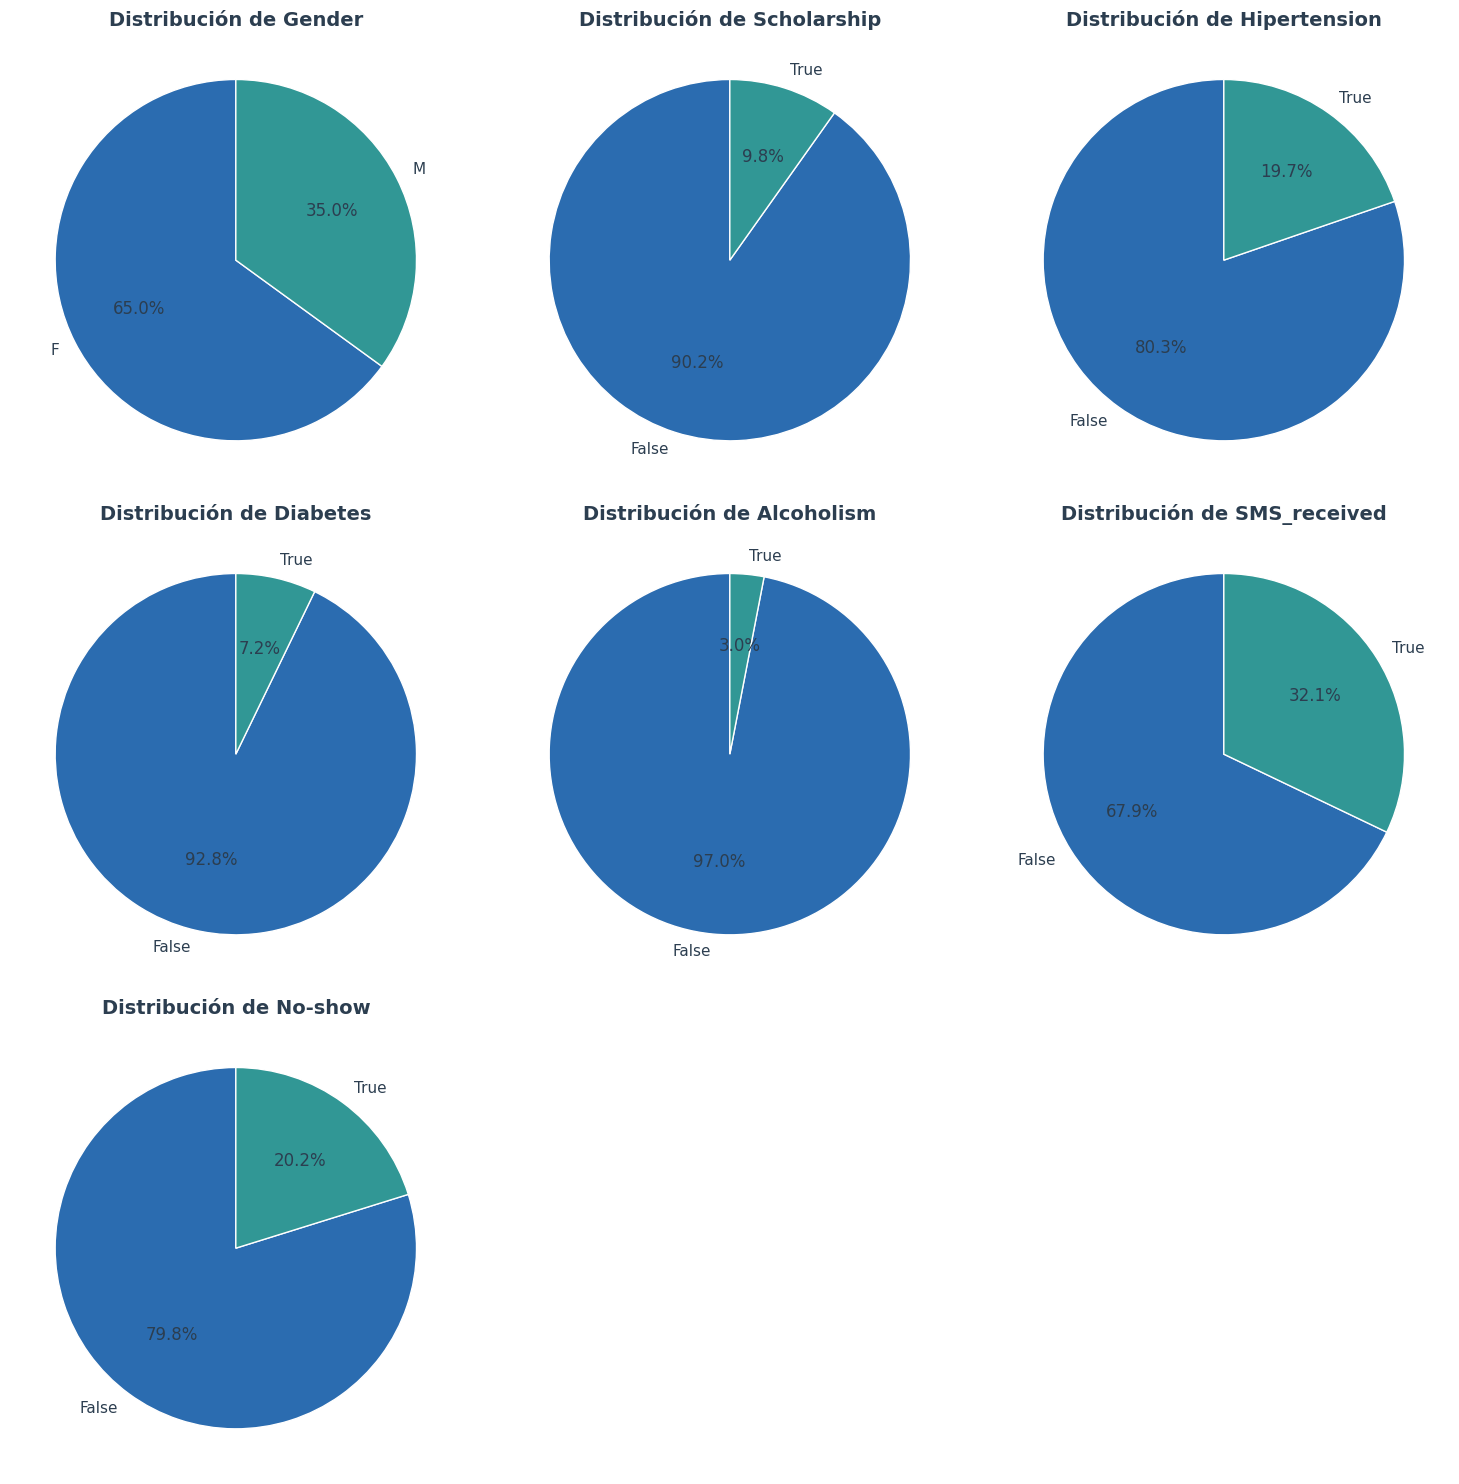

In [41]:
columnas_pie = ["Gender","Scholarship","Hipertension","Diabetes","Alcoholism","SMS_received","No-show"]

n_cols = 3
n_rows = math.ceil(len(columnas_pie)/n_cols)

fig, axes = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,5*n_rows))

axes = axes.flatten() if hasattr(axes, "flatten") else [axes] #asegurar que axes sea un array plano

for i, col in enumerate(columnas_pie):
  conteos = df[col].value_counts() #Contar las frecuencias de cada categoría

  axes[i].pie(
      conteos,
      labels=conteos.index,
      colors=sns.color_palette(medical_colors),
      autopct="%1.1f%%",
      startangle=90,
  )
  axes[i].set_title(f"Distribución de {col}", fontsize=14, fontweight="bold")

for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

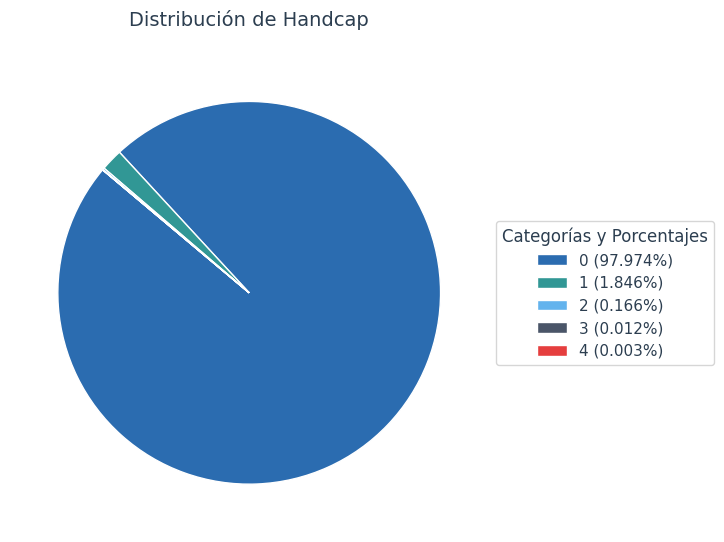

In [42]:
frecuencias = df['Handcap'].value_counts()

porcentajes = (
    df["Handcap"].value_counts(normalize=True) * 100
)
etiquetas_leyenda = [
    f"{cat} ({pct:.3f}%)" for cat, pct in zip(frecuencias.index, porcentajes)
]

plt.figure(figsize=(7, 6))

rebanadas, _ = plt.pie(frecuencias, startangle=140)

plt.legend(
    rebanadas,
    etiquetas_leyenda,
    title="Categorías y Porcentajes",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=True,
)

plt.title("Distribución de Handcap", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

## Distribuciones de variables numéricas

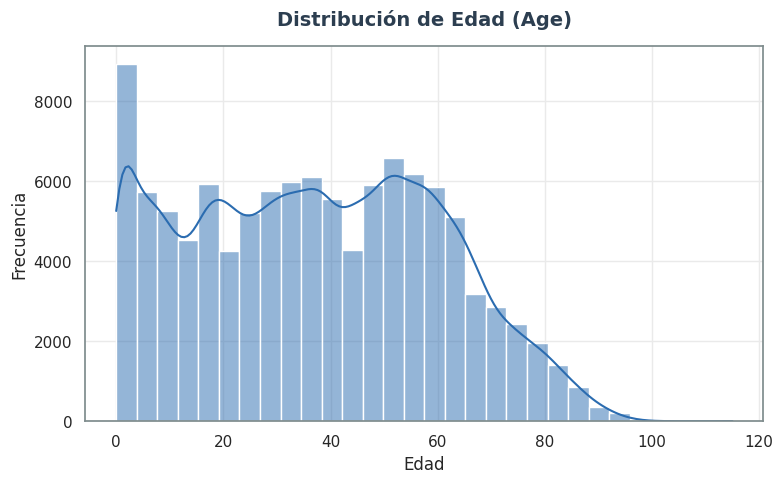

In [43]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', bins=30, kde=True, color=medical_colors[0])

# Personalizar títulos y etiquetas
plt.title('Distribución de Edad (Age)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Edad', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

plt.tight_layout()
plt.show()

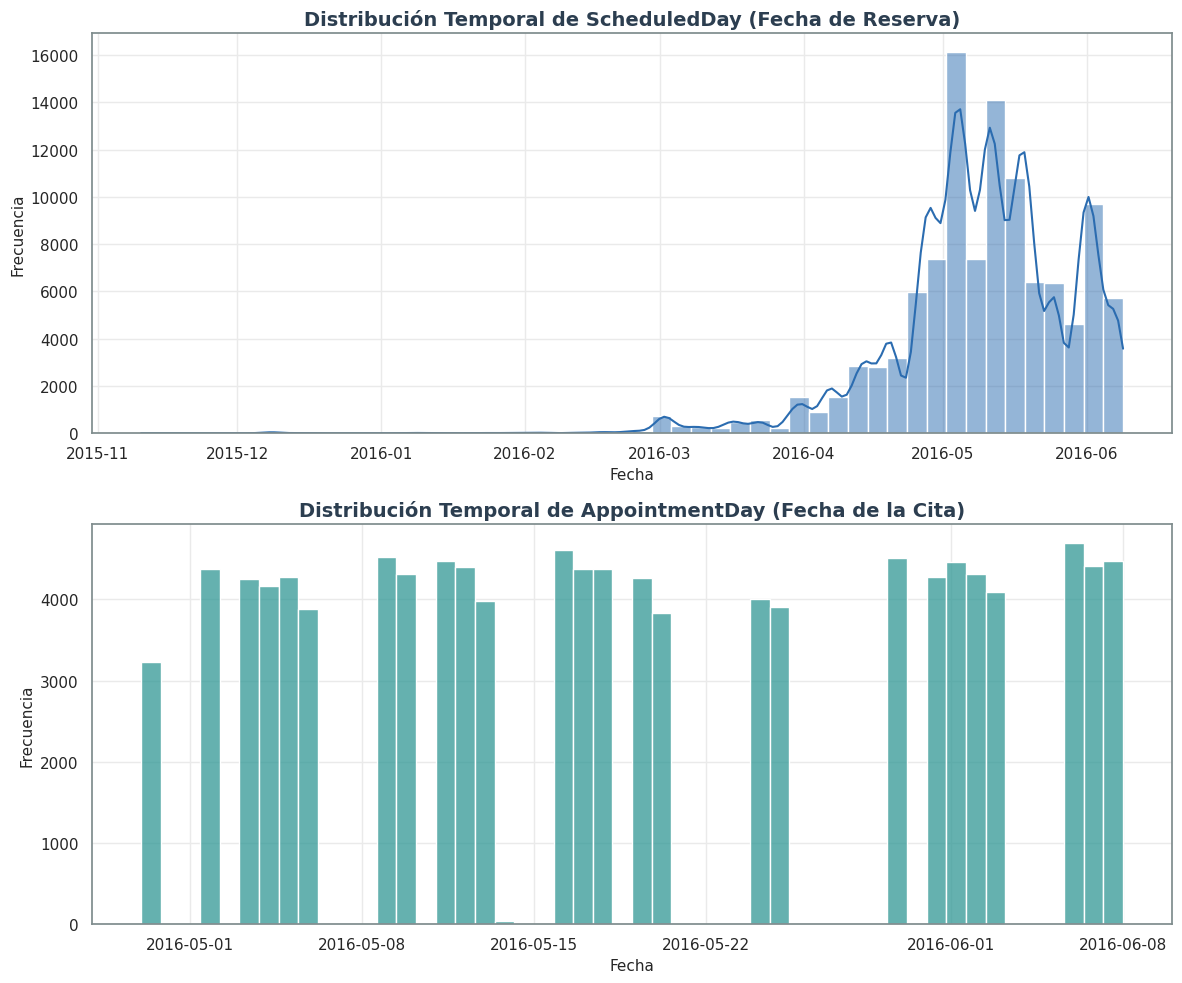

In [44]:
# Crear una figura con 2 subgráficos verticales
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=False)

# Histograma para ScheduledDay
sns.histplot(data=df, x='ScheduledDay', bins=50, ax=axes[0], color=medical_colors[0], kde=True)
axes[0].set_title('Distribución Temporal de ScheduledDay (Fecha de Reserva)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Fecha', fontsize=11)
axes[0].set_ylabel('Frecuencia', fontsize=11)

# Histograma para AppointmentDay
sns.histplot(data=df, x='AppointmentDay', bins=50, ax=axes[1], color=medical_colors[1], kde=False)
axes[1].set_title('Distribución Temporal de AppointmentDay (Fecha de la Cita)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Fecha', fontsize=11)
axes[1].set_ylabel('Frecuencia', fontsize=11)

plt.tight_layout()
plt.show()

## Relación de variables con No-Show

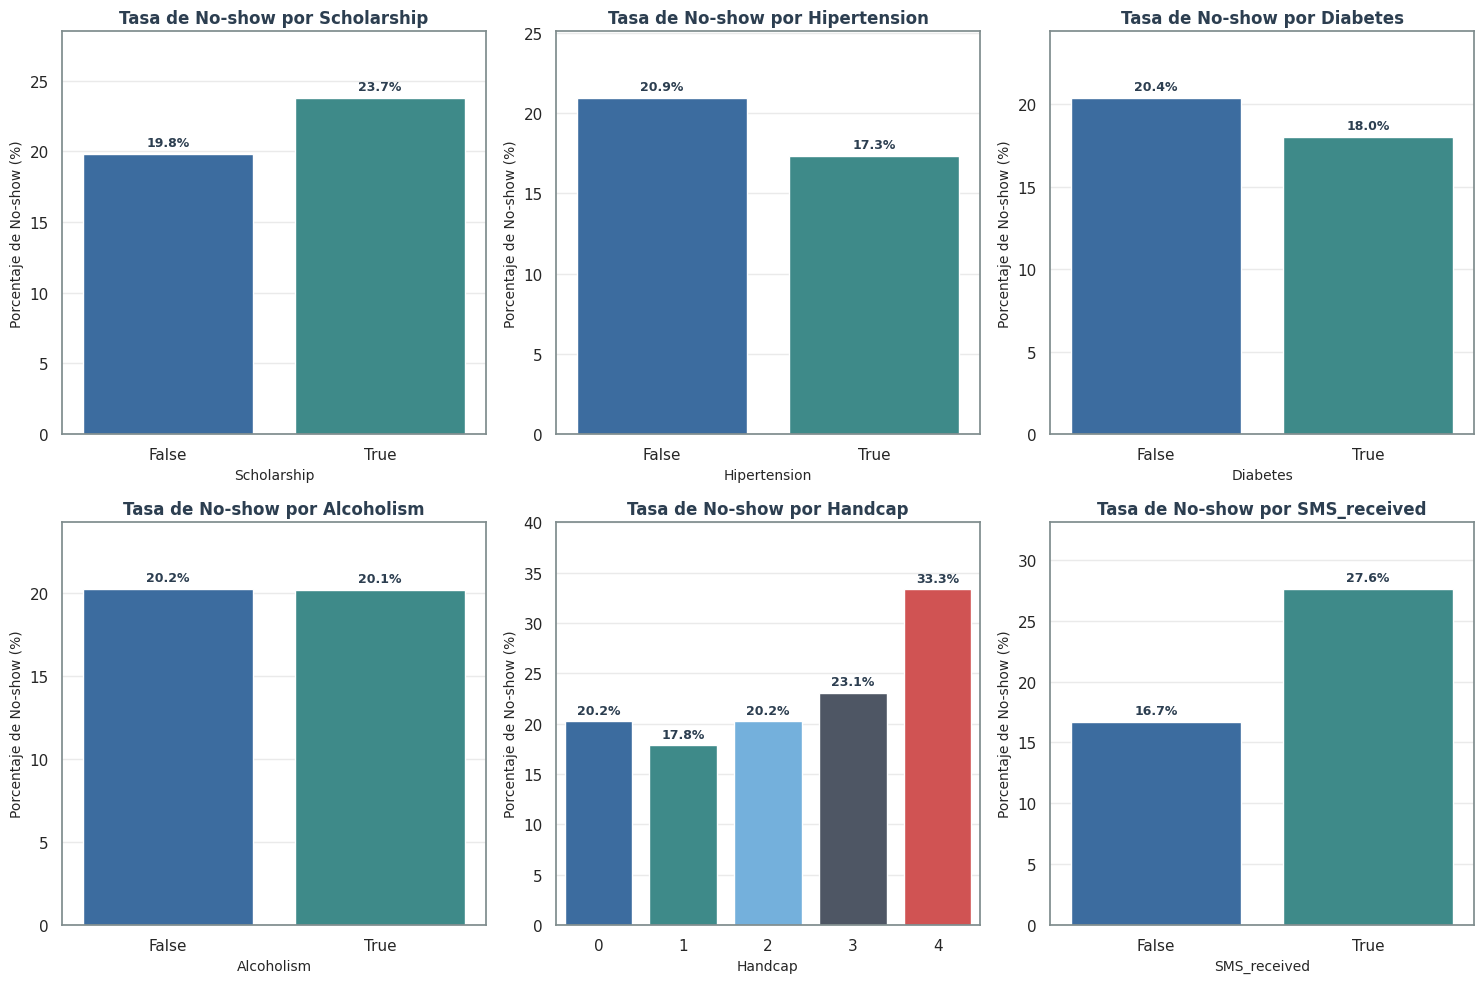

In [45]:
# Columnas a graficar
columnas_comparar = ['Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received']

# Configurar la cuadrícula de gráficos
n_cols = 3
n_rows = math.ceil(len(columnas_comparar) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for i, col in enumerate(columnas_comparar):
    # Como 'No-show' es bool (True=1, False=0), .mean() calcula directo la tasa de ausencia
    grouped_data = (
        df.groupby(col, observed=False)['No-show']
        .mean()
        .mul(100)
        .reset_index(name='No-show_percentage')
    )

    # Ajustar medical_colors al número exacto de categorías (ej. 2 para bool, 5 para Handcap)
    n_categorias = len(grouped_data)
    paleta = sns.color_palette(medical_colors, n_colors=n_categorias)

    # Graficar
    sns.barplot(
        data=grouped_data,
        x=col,
        y='No-show_percentage',
        order=grouped_data[col],
        hue=col,
        palette=paleta,
        legend=False,
        ax=axes[i]
    )

    # Personalizar subgráfico
    axes[i].set_title(f'Tasa de No-show por {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Porcentaje de No-show (%)', fontsize=10)

    # Ajustar límite Y de forma dinámica
    max_val = grouped_data['No-show_percentage'].max()
    axes[i].set_ylim(0, max(max_val * 1.2, 10))

    # Añadir valores sobre las barras
    for idx, row in grouped_data.iterrows():
        axes[i].text(
            idx,
            row['No-show_percentage'] + (max_val * 0.02 + 0.1),
            f"{row['No-show_percentage']:.1f}%",
            ha='center',
            fontweight='bold',
            fontsize=9
        )

# Eliminar ejes sobrantes si los hay
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

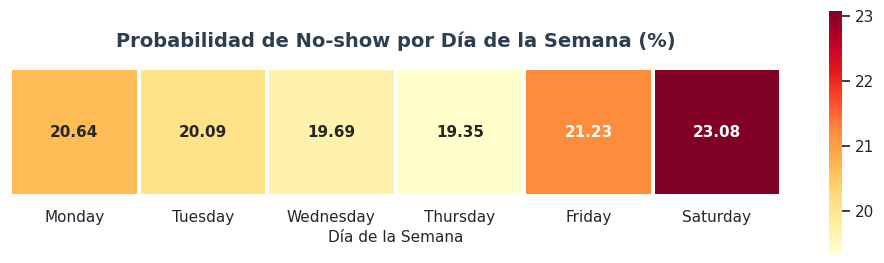

In [47]:
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

# 1. Calcular porcentaje de No-show, ordenar de lunes a sábado y transponer en una sola cadena
heatmap_data = (
    df.groupby('AppointmentDayOfWeek')['No-show']
    .mean()
    .mul(100)
    .reindex(dias_orden)
    .to_frame(name='No-show (%)')
    .T
)

# 2. Graficar el mapa de calor
plt.figure(figsize=(10, 2.8))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    cbar=True,
    linewidths=1.5,
    square=True,
    annot_kws={"weight": "bold", "size": 11}
)

plt.title("Probabilidad de No-show por Día de la Semana (%)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Día de la Semana", fontsize=11)
plt.yticks([])
plt.tight_layout()
plt.show()